<!-- project-navigation -->
# 11_model_XGBoost
Role: Model experiments and analysis.

See [notebook guide](README.md) and [model comparison](../reports/model_comparison.md). Historical code and outputs are retained; run with the project root as working directory.


Étape 1 — XGBoost sur la table actuelle (baseline enrichie) ✅

On va d'abord tester XGBoost sur :

application_train_encode.csv

Pourquoi ?

même base de données que ta Logistic Regression ;
comparaison juste entre les modèles ;
on mesure uniquement l'effet du changement d'algorithme.

Résultat attendu :

Modèle	Données	Objectif
Logistic Regression	application_train_encode	Baseline
XGBoost	application_train_encode	Améliorer la performance
Étape 2 — XGBoost sur la grande table finale 🚀

Après, on utilisera :

train_final.csv

Cette table devrait contenir :

les variables de application_train ;
les features agrégées de bureau ;
les features de bureau_balance ;
les historiques de paiement (installments) ;
éventuellement d'autres tables.

On aura alors :

Modèle	Données
Logistic Regression	application_train_encode
XGBoost	train_final

L'objectif sera de voir l'impact de l'ajout des informations historiques.

La logique de présentation sera très intéressante :

Modèle simple interprétable

Logistic Regression sur les informations client de base.

Modèle avancé

XGBoost pour capturer des relations plus complexes.

Enrichissement des données

Ajout des historiques financiers pour améliorer la prédiction.

In [9]:
import os
print(os.getcwd())

c:\Users\Asus\OneDrive\Bureau\FinTech


In [1]:
import sys
print(sys.executable)

c:\Users\Asus\OneDrive\Bureau\FinTech\.venv\Scripts\python.exe


In [2]:
import sys
print(sys.executable)

!{sys.executable} -m pip show xgboost

c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Scripts\python.exe
Name: xgboost
Version: 3.4.0
Summary: XGBoost Python Package
Home-page: 
Author: 
Author-email: Hyunsu Cho <chohyu01@cs.washington.edu>, Jiaming Yuan <jm.yuan@outlook.com>
License-Expression: Apache-2.0
Location: c:\Users\Asus\OneDrive\Bureau\FinTech\.venv-1\Lib\site-packages
Requires: numpy, scipy
Required-by: 


In [3]:
from xgboost import XGBClassifier

print("XGBoost importé avec succès")

XGBoost importé avec succès


In [4]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=10,
    random_state=42,
    eval_metric="logloss"
)

In [13]:
import pandas as pd

application_encode = pd.read_csv(
    "data/processed/application_train_encode.csv"
)

application_encode.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,ORGANIZATION_TYPE_Trade: type 4,ORGANIZATION_TYPE_Trade: type 5,ORGANIZATION_TYPE_Trade: type 6,ORGANIZATION_TYPE_Trade: type 7,ORGANIZATION_TYPE_Transport: type 1,ORGANIZATION_TYPE_Transport: type 2,ORGANIZATION_TYPE_Transport: type 3,ORGANIZATION_TYPE_Transport: type 4,ORGANIZATION_TYPE_University,ORGANIZATION_TYPE_XNA
0,100002,1,0,1,0,1,0,202500.0,406597.5,24700.5,...,0,0,0,0,0,0,0,0,0,0
1,100003,0,0,0,0,0,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0,0,0,0,0,0
2,100004,0,1,1,1,1,0,67500.0,135000.0,6750.0,...,0,0,0,0,0,0,0,0,0,0
3,100006,0,0,0,0,1,0,135000.0,312682.5,29686.5,...,0,0,0,0,0,0,0,0,0,0
4,100007,0,0,1,0,1,0,121500.0,513000.0,21865.5,...,0,0,0,0,0,0,0,0,0,0


In [15]:
X = application_encode.drop(
    ["TARGET", "SK_ID_CURR"],
    axis=1
)

y = application_encode["TARGET"]
print(X.shape)
print(y.shape)

(307511, 163)
(307511,)


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape)
print(X_test.shape)

(246008, 163)
(61503, 163)


In [17]:
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

TARGET
0    226148
1     19860
Name: count, dtype: int64
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


In [ ]:
print("Dans X :")
print(X.select_dtypes(include="object").columns)

print("\nDans X_train :")
print(X_train.select_dtypes(include="object").columns)

Dans X :
Index([], dtype='str')

Dans X_train :
Index(['HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'age_tranche'], dtype='str')


C:\Users\Asus\AppData\Local\Temp\ipykernel_23688\1207329651.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X_train.select_dtypes(include="object").columns)


In [35]:
X = application_encode.drop(
    ["TARGET", "SK_ID_CURR"],
    axis=1
)

y = application_encode["TARGET"]

In [38]:
X.select_dtypes(include=["str", "object"]).columns

Index(['HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'age_tranche'], dtype='str')

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [40]:
print(X_train.shape)
print(X_train.dtypes.value_counts())

(246008, 163)
int64      136
float64     24
str          3
Name: count, dtype: int64


In [43]:
print(X_train.select_dtypes(include=["str"]).columns)

Index(['HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'age_tranche'], dtype='str')


In [44]:
X_train = pd.get_dummies(
    X_train,
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    drop_first=True
)

In [45]:
X_train, X_test = X_train.align(
    X_test,
    join="left",
    axis=1,
    fill_value=0
)

In [46]:
print(X_train.select_dtypes(include=["str"]).columns)
print(X_train.shape)
print(X_test.shape)

Index([], dtype='str')
(246008, 174)
(61503, 174)


In [47]:
model_xgb.fit(
    X_train,
    y_train
)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [48]:
y_pred_xgb = model_xgb.predict(X_test)

y_proba_xgb = model_xgb.predict_proba(X_test)[:,1]

In [49]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

print(confusion_matrix(y_test, y_pred_xgb))

print(classification_report(y_test, y_pred_xgb))

print("ROC-AUC :", roc_auc_score(y_test, y_proba_xgb))

[[42665 13873]
 [ 1847  3118]]
              precision    recall  f1-score   support

           0       0.96      0.75      0.84     56538
           1       0.18      0.63      0.28      4965

    accuracy                           0.74     61503
   macro avg       0.57      0.69      0.56     61503
weighted avg       0.90      0.74      0.80     61503

ROC-AUC : 0.7607439525830055


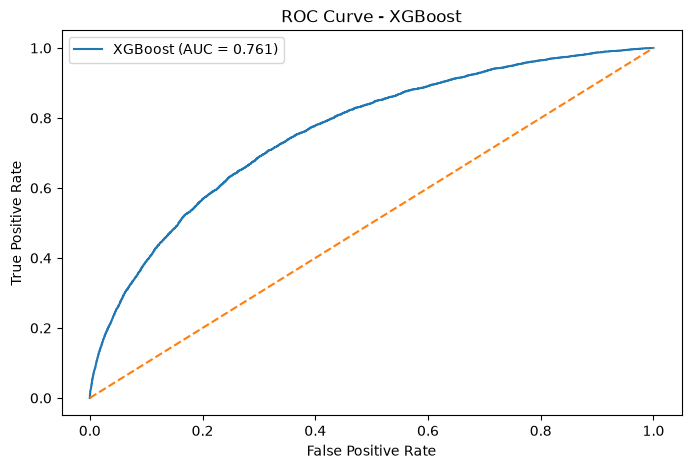

In [50]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Probabilités de la classe défaut (1)
y_proba_xgb = model_xgb.predict_proba(X_test)[:, 1]

# Calcul de la courbe ROC
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba_xgb
)

# Calcul AUC
auc_xgb = roc_auc_score(
    y_test,
    y_proba_xgb
)

# Affichage
plt.figure(figsize=(8,5))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {auc_xgb:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")

plt.legend()

plt.show()

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

# Récupérer l'importance des variables
importance_xgb = pd.DataFrame({
    "Variable": X_train.columns,
    "Importance": model_xgb.feature_importances_
})

# Trier les variables les plus importantes
top_features_xgb = importance_xgb.sort_values(
    by="Importance",
    ascending=False
).head(10)

top_features_xgb

,Variable,Importance
32,EXT_SOURCE_3,0.047124
31,EXT_SOURCE_2,0.044059
65,NAME_EDUCATION_TYPE_Higher education,0.033859
1,CODE_GENDER,0.024334
68,NAME_EDUCATION_TYPE_Secondary / secondary special,0.021767
30,EXT_SOURCE_1,0.018634
2,FLAG_OWN_CAR,0.017582
38,FLAG_DOCUMENT_3,0.013955
0,NAME_CONTRACT_TYPE,0.012661
81,OCCUPATION_TYPE_Core staff,0.011084


 5. Modélisation avancée : XGBoost

Après avoir construit une première approche avec la Logistic Regression comme modèle baseline, 
un modèle avancé basé sur les arbres de décision a été testé afin de capturer des relations 
non linéaires entre les variables et améliorer la prédiction du risque de défaut.

## 5.1 Présentation du modèle

Le modèle utilisé est **XGBoost (Extreme Gradient Boosting)**.

Objectifs :
- Améliorer les performances par rapport au modèle baseline.
- Capturer des interactions complexes entre les variables financières et socio-économiques.
- Comparer ses résultats avec la Logistic Regression.

Le déséquilibre des classes a été pris en compte lors de l'évaluation car la variable cible TARGET présente :

- Classe 0 : clients ayant remboursé leur crédit
- Classe 1 : clients en défaut de paiement

## 5.2 Entraînement du modèle XGBoost

Les données utilisées correspondent à la table finale préparée :

- Variables encodées
- Valeurs manquantes traitées
- Variables sélectionnées
- Données séparées en train/test

Dimensions :

- X_train : 246 008 observations et 174 variables
- X_test : 61 503 observations et 174 variables
## 5.3 Evaluation du modèle XGBoost

Le modèle a été évalué avec plusieurs métriques adaptées à un problème de classification déséquilibré :

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Matrice de confusion

Résultats obtenus :

| Métrique | Résultat |
|----------|----------|
| Accuracy | 74% |
| Recall défaut | 63% |
| F1-score défaut | 28% |
| ROC-AUC | 0.761 |

La matrice de confusion obtenue :

[[42665 13873]
 [ 1847  3118]]

Interprétation :

- 3118 clients en défaut ont été correctement détectés.
- 1847 défauts n'ont pas été identifiés par le modèle.
- Le modèle présente une capacité correcte de discrimination entre clients à risque et clients solvables.
## 5.4 Courbe ROC

La courbe ROC permet d'évaluer la capacité du modèle à distinguer les deux classes.

Le modèle XGBoost obtient une valeur :

**ROC-AUC = 0.761**

Une valeur proche de 1 indique une meilleure capacité de séparation entre les classes.
## 5.5 Importance des variables avec XGBoost

Contrairement à la Logistic Regression qui fournit des coefficients interprétables, 
XGBoost mesure l'importance des variables selon leur contribution dans les arbres de décision.

Les variables les plus influentes sont :

| Variable | Importance |
|----------|------------|
| EXT_SOURCE_3 | 0.047 |
| EXT_SOURCE_2 | 0.044 |
| NAME_EDUCATION_TYPE_Higher education | 0.034 |
| CODE_GENDER | 0.024 |
| NAME_EDUCATION_TYPE_Secondary / secondary special | 0.022 |

Les variables externes de solvabilité (EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3) 
sont les facteurs les plus importants dans la prédiction du risque de défaut.
# 6. Comparaison finale des modèles

Deux approches principales ont été comparées :

- Logistic Regression sans ACP
- Logistic Regression avec ACP
- XGBoost

| Modèle | Accuracy | Recall défaut | F1-score défaut | ROC-AUC |
|--------|----------|---------------|-----------------|---------|
| Logistic Regression sans ACP | 71% | 70% | 28% | 0.770 |
| Logistic Regression avec ACP | 69% | 69% | 27% | 0.752 |
| XGBoost | 74% | 63% | 28% | 0.761 |

## Analyse

XGBoost obtient la meilleure accuracy grâce à sa capacité à modéliser des relations complexes.

Cependant, la Logistic Regression sans ACP présente :
- Un meilleur ROC-AUC.
- Un meilleur Recall sur la classe défaut.
- Une meilleure interprétabilité grâce aux coefficients.

Dans un contexte bancaire, l'explicabilité des décisions est un critère important.
# 7. Choix du modèle final

Le modèle retenu comme baseline finale est :

## Logistic Regression sans ACP

Justification :

- Performances compétitives.
- Bonne détection des clients en défaut.
- Interprétation directe des facteurs influençant le risque grâce à l'analyse des coefficients.
- Adapté à un contexte financier nécessitant de l'explicabilité.

XGBoost reste une approche intéressante pour de futures améliorations après optimisation des hyperparamètres.
# 8. Perspectives

Les améliorations possibles sont :

- Optimisation des hyperparamètres XGBoost.
- Test d'autres modèles comme LightGBM ou CatBoost.
- Utilisation de méthodes XAI avancées comme SHAP.
- Mise en place d'un système de suivi du risque de crédit en production.

--------------------------------------------------------------------------------------------

In [67]:
from sklearn.ensemble import RandomForestClassifier

In [1]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\Asus\OneDrive\Bureau\FinTech
['.agents', '.git', '.venv', '.venv-1', '.vscode', 'analyse_select_distinct_valeurs_manquantes.xlsx', 'Analyse_SELECT_DISTINCT_variables.xlsx', 'Analyse_SELECT_DISTINCT_variables_complete.xlsx', 'analyse_valeurs_distinctes_variables.xlsx', 'analyse_variables_distinctes.xlsx', 'analyse_variables_imputation.xlsx', 'app', 'data', 'docs', 'features', 'features_ajoutees_feature_engineering.xlsx', 'features_engineering_description.xlsx', 'models', 'notebooks', 'reports', 'src']


In [2]:
print(os.listdir())

['.agents', '.git', '.venv', '.venv-1', '.vscode', 'analyse_select_distinct_valeurs_manquantes.xlsx', 'Analyse_SELECT_DISTINCT_variables.xlsx', 'Analyse_SELECT_DISTINCT_variables_complete.xlsx', 'analyse_valeurs_distinctes_variables.xlsx', 'analyse_variables_distinctes.xlsx', 'analyse_variables_imputation.xlsx', 'app', 'data', 'docs', 'features', 'features_ajoutees_feature_engineering.xlsx', 'features_engineering_description.xlsx', 'models', 'notebooks', 'reports', 'src']


In [4]:
print("Fichiers dans models :")
print(os.listdir("models"))

Fichiers dans models :
[]


In [5]:
print("\nFichiers dans notebooks :")
print(os.listdir("notebooks"))


Fichiers dans notebooks :
['01_data_understanding.ipynb', '02_data_understanding_bureau.ipynb', '03_data_understanding_bureau_balance.ipynb', '04_data_understanding_installments_payments.ipynb', '05_understanding_application_test.ipynb', '06_understanding_previous_application.ipynb', '07_data_understandin_pos_cash.ipynb', '08_data_understandin_credit_card_balance.ipynb', '09_data_understanding_application_test.ipynb', '10_modeling.ipynb', '11_model_XGBoost.ipynb', '12_model_reg_opt.ipynb', '13_RandomForest.ipynb', 'complementaire.ipynb']
